In [215]:
##########################
# RDE NUMERICAL SOLUTION #
##########################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np 

In [216]:
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

def funVasicek(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
def funCIR(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultVasicek = solve_ivp(funVasicek, (0, 10), U_0, t_eval=t_pts, method='RK45')

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultCIR = solve_ivp(funCIR, (0, 10), U_0, t_eval=t_pts, method='RK45')

resultVasicek, resultCIR

(  message: 'The solver successfully reached the end of the integration interval.'
      nfev: 62
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])
  t_events: None
         y: array([[ 0.        , -0.15756962, -0.52434511, -1.0035023 , -1.54479142,
         -2.12158378, -2.71809852, -3.32649961, -3.94153923, -4.56037643,
         -5.18163147],
        [ 0.        , -0.752042  , -1.16469653, -1.39116122, -1.51567464,
         -1.58347721, -1.62125786, -1.64156334, -1.65275758, -1.65908957,
         -1.66236531],
        [ 0.        , -0.78696794, -1.26425539, -1.55374235, -1.72946291,
         -1.83572248, -1.90054142, -1.93954786, -1.96325109, -1.97775944,
         -1.98638789]])
  y_events: None,
   message: 'The solver successfully reached the end of the integration interval.'
      nfev: 68
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array

In [217]:
###########################
# SWAPTION EXERCISE BOUND #
###########################

# Consider swaption given by t=0, S=5, T=10 and yearly cashflows in between

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [218]:
#ATMF strike Vasicek + sanity check

VasPtT1 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*0.05+resultVasicek.y[2,1]*0.05)
VasPtT2 = np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*0.05+resultVasicek.y[2,2]*0.05)
VasPtT3 = np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*0.05+resultVasicek.y[2,3]*0.05)
VasPtT4 = np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*0.05+resultVasicek.y[2,4]*0.05)
VasPtS = np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*0.05+resultVasicek.y[2,5]*0.05)
VasPtT6 = np.exp(resultVasicek.y[0,6]+resultVasicek.y[1,6]*0.05+resultVasicek.y[2,6]*0.05)
VasPtT7 = np.exp(resultVasicek.y[0,7]+resultVasicek.y[1,7]*0.05+resultVasicek.y[2,7]*0.05)
VasPtT8 = np.exp(resultVasicek.y[0,8]+resultVasicek.y[1,8]*0.05+resultVasicek.y[2,8]*0.05)
VasPtT9 = np.exp(resultVasicek.y[0,9]+resultVasicek.y[1,9]*0.05+resultVasicek.y[2,9]*0.05)
VasPtT = np.exp(resultVasicek.y[0,10]+resultVasicek.y[1,10]*0.05+resultVasicek.y[2,10]*0.05)

VasATMFSwapK = (VasPtS - VasPtT)/(VasPtT6 + VasPtT7 + VasPtT8 + VasPtT9 + VasPtT)
KVasicek = VasATMFSwapK
VasATMFSwapK, VasPtS-KVasicek*VasPtT6-KVasicek*VasPtT7-KVasicek*VasPtT8-KVasicek*VasPtT9-(1+KVasicek)*VasPtT

(0.8377629312333242, 1.734723475976807e-18)

In [219]:
#ATMF strike CIR + sanity check

CIRPtT1 = np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*0.05+resultCIR.y[2,1]*0.05)
CIRPtT2 = np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*0.05+resultCIR.y[2,2]*0.05)
CIRPtT3 = np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*0.05+resultCIR.y[2,3]*0.05)
CIRPtT4 = np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*0.05+resultCIR.y[2,4]*0.05)
CIRPtS = np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*0.05+resultCIR.y[2,5]*0.05)
CIRPtT6 = np.exp(resultCIR.y[0,6]+resultCIR.y[1,6]*0.05+resultCIR.y[2,6]*0.05)
CIRPtT7 = np.exp(resultCIR.y[0,7]+resultCIR.y[1,7]*0.05+resultCIR.y[2,7]*0.05)
CIRPtT8 = np.exp(resultCIR.y[0,8]+resultCIR.y[1,8]*0.05+resultCIR.y[2,8]*0.05)
CIRPtT9 = np.exp(resultCIR.y[0,9]+resultCIR.y[1,9]*0.05+resultCIR.y[2,9]*0.05)
CIRPtT = np.exp(resultCIR.y[0,10]+resultCIR.y[1,10]*0.05+resultCIR.y[2,10]*0.05)

CIRATMFSwapK = (CIRPtS - CIRPtT)/(CIRPtT6 + CIRPtT7 + CIRPtT8 + CIRPtT9 + CIRPtT)
KCIR = CIRATMFSwapK
CIRATMFSwapK, CIRPtS-KCIR*CIRPtT6-KCIR*CIRPtT7-KCIR*CIRPtT8-KCIR*CIRPtT9-(1+KCIR)*CIRPtT

(0.9299859409740431, -5.204170427930421e-18)

In [220]:
#################################################
# FETCH QUANTILES FROM RESPECTIVE DISTRIBUTIONS #
#################################################

from scipy.stats import norm
from scipy.stats import ncx2
import numpy as np

In [261]:
#Vasicek 1st factor distr.

r0 = 0.05
expiryT = 5
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
EV1 = r0*np.exp(-kappa1*expiryT)+theta1*(1-np.exp(-kappa1*expiryT))
Var1 = (sigma1**2/kappa1)*(1-np.exp(-2*kappa1*expiryT))
lowerquantile1 = norm.ppf((1-0.9545)/2, loc=EV1, scale=Var1)
upperquantile1 = norm.ppf((1+0.9545)/2, loc=EV1, scale=Var1)

Var1, (lowerquantile1, EV1, upperquantile1)

(0.06650141652155558,
 (0.249571530505351, 0.38257452607124764, 0.5155775216371442))

In [276]:
#Vasicek 2nd factor distr.

r0 = 0.05
expiryT = 5
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
EV2 = r0*np.exp(-kappa2*expiryT)+theta2*(1-np.exp(-kappa2*expiryT))
Var2 = (sigma2**2/kappa2)*(1-np.exp(-2*kappa2*expiryT))
lowerquantile2 = norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2)
upperquantile2 = norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2)

Var2, (lowerquantile2, EV2, upperquantile2)

(0.019865241060018295,
 (0.23974821967533397, 0.2794787503440253, 0.3192092810127166))

In [277]:
#CIR 1st factor distr.

r01 = 0.05
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
expiryT = 5
dt = expiryT - 0

mu1 = 4 * theta1 * kappa1 / sigma1**2
ncx2_init1 = r01
non_central1 = 4 * kappa1 * np.exp(-kappa1 * dt) / (sigma1**2 * (1 - np.exp(-kappa1 * dt))) * ncx2_init1
scale1 = sigma1**2 * (1-np.exp(-kappa1 * dt)) / (4 * kappa1)
X_1_new = ncx2(df=mu1,nc=non_central1,scale=scale1)
EV1newCIR = (mu1+non_central1)*scale1

X_1_new.ppf(0.5), X_1_new.var(), (X_1_new.ppf((1-0.9545)/2), EV1newCIR, X_1_new.ppf((1+0.9545)/2)), (X_1_new.ppf(1-0.9545), EV1newCIR, X_1_new.ppf(0.9545))

(0.3720023453599923,
 0.012196422593183173,
 (0.19487952478665166, 0.38257452607124764, 0.6336219896108802),
 (0.21732813018747554, 0.38257452607124764, 0.5870850867261865))

In [280]:
#CIR 2nd factor distr.

r02 = 0.05
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
expiryT = 5
dt = expiryT - 0

mu2 = 4 * theta2 * kappa2 / sigma2**2
ncx2_init2 = r02
non_central2 = 4 * kappa2 * np.exp(-kappa2 * dt) / (sigma2**2 * (1 - np.exp(-kappa2 * dt))) * ncx2_init2
scale2 = sigma2**2 * (1-np.exp(-kappa2 * dt)) / (4 * kappa2)
X_2_new = ncx2(df=mu2,nc=non_central2,scale=scale2)
EV2newCIR = (mu2+non_central2)*scale2

X_2_new.ppf(0.5), X_2_new.var(), (X_2_new.ppf((1-0.9545)/2), EV2newCIR, X_2_new.ppf((1+0.9545)/2)), (X_2_new.ppf(1-0.9545), EV2newCIR, X_2_new.ppf(0.9545))

(0.2763809054033594,
 0.002603050900878677,
 (0.1870085832617806, 0.27947875034402525, 0.39052671495758956),
 (0.19932889034906184, 0.27947875034402525, 0.37113242114207795))

In [282]:
################################
# PLUG Y_S INTO EXERCISE BOUND #
################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [292]:
# Solve P(x)-1=0 <=> P(x)=1

VasEnd1ExerciseBound = lambda Y1S1 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S1+resultVasicek.y[2,1]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S1+resultVasicek.y[2,2]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S1+resultVasicek.y[2,3]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S1+resultVasicek.y[2,4]*lowerquantile2)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S1+resultVasicek.y[2,5]*lowerquantile2)-1
VasY1S1_init_guess = 0.2
VasSolY1S1 = fsolve(VasEnd1ExerciseBound, VasY1S1_init_guess)

VasEnd2ExerciseBound = lambda Y1S2 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S2+resultVasicek.y[2,1]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S2+resultVasicek.y[2,2]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S2+resultVasicek.y[2,3]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S2+resultVasicek.y[2,4]*upperquantile2)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S2+resultVasicek.y[2,5]*upperquantile2)-1
VasY1S2_init_guess = 0.2
VasSolY1S2 = fsolve(VasEnd2ExerciseBound, VasY1S2_init_guess)

x = [VasSolY1S1[0],VasSolY1S2[0]]
y = [lowerquantile2, upperquantile2]

#slope coef[0], intercept coef[1]

coefVas = np.polyfit(y,x,1)

(VasSolY1S1[0],VasSolY1S2[0]), (lowerquantile2, upperquantile2), coefVas, KVasicek

((0.3310619286393963, 0.24420977581838274),
 (0.23974821967533397, 0.3192092810127166),
 array([-1.09301526,  0.59311039]),
 0.8377629312333242)

In [296]:
# Solve P(x)-1=0 <=> P(x)=1

CIREnd1ExerciseBound = lambda Y1S1 : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S1+resultCIR.y[2,1]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*Y1S1+resultCIR.y[2,2]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*Y1S1+resultCIR.y[2,3]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*Y1S1+resultCIR.y[2,4]*X_2_new.ppf((1-0.9545)/2))-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*Y1S1+resultCIR.y[2,5]*X_2_new.ppf((1-0.9545)/2))
CIRY1S1_init_guess = 0.2
CIRSolY1S1 = fsolve(CIREnd1ExerciseBound, CIRY1S1_init_guess)

CIREnd2ExerciseBound = lambda Y1S2 : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S2+resultCIR.y[2,1]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*Y1S2+resultCIR.y[2,2]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*Y1S2+resultCIR.y[2,3]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*Y1S2+resultCIR.y[2,4]*X_2_new.ppf((1+0.9545)/2))-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*Y1S2+resultCIR.y[2,5]*X_2_new.ppf((1+0.9545)/2))
CIRY1S2_init_guess = 0.2
CIRSolY1S2 = fsolve(CIREnd2ExerciseBound, CIRY1S2_init_guess)

CIRx = [CIRSolY1S1[0],CIRSolY1S2[0]]
CIRy = [X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)]

#slope coef[0], intercept coef[1]

coefCIR = np.polyfit(CIRy,CIRx,1)

(CIRSolY1S1[0], CIRSolY1S2[0]), (X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)), X_2_new.ppf(0.5), coefCIR, KCIR

((0.45752631120695025, 0.23298430040887225),
 (0.1870085832617806, 0.39052671495758956),
 0.2763809054033594,
 array([-1.10330224,  0.6638533 ]),
 0.9299859409740431)

In [214]:
###################################
# SIMULATION a.k.a. "TRUE PRICES" #
###################################

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.axes as ax
from scipy import integrate
from scipy.stats import ncx2
from IPython.display import display

In [284]:
def VasicekJPDF(N):
    W_1 = [norm.rvs(loc=EV1, scale=Var1)]
    W_2 = [norm.rvs(loc=EV2, scale=Var2)]
    
    for i in range(N):
        r_new1 = norm.rvs(loc=EV1, scale=Var1)
        r_new2 = norm.rvs(loc=EV2, scale=Var2)
        W_1.append(r_new1)
        W_2.append(r_new2)
        
    return [W_1, W_2]

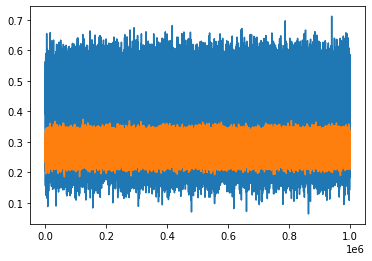

In [325]:
VasicekList = VasicekJPDF(1000000)
plt.plot(VasicekList[0])
plt.plot(VasicekList[1])
plt.show()

(0.20559959135426564, 0.35335790933378497)

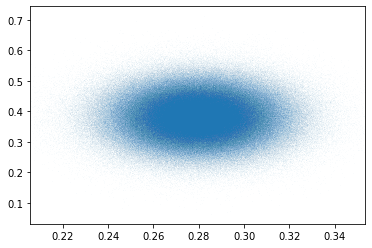

In [326]:
plt.scatter(VasicekList[1],VasicekList[0],s=0.00005)
plt.xlim(norm.ppf(1-0.9999, loc=EV2, scale=Var2), norm.ppf(0.9999, loc=EV2, scale=Var2))

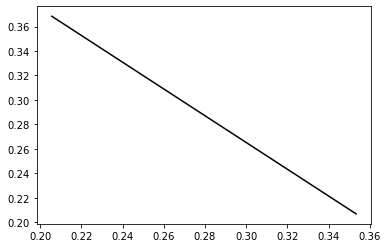

In [297]:
ApproxEBVasicek = lambda x: coefVas[0]*x+coefVas[1]
x = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 10000)
plt.plot(x, ApproxEBVasicek(x),color='k')

In [300]:
EBVasicek = lambda z : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*z+resultVasicek.y[2,1]*w)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*z+resultVasicek.y[2,2]*w)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*z+resultVasicek.y[2,3]*w)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*z+resultVasicek.y[2,4]*w)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*z+resultVasicek.y[2,5]*w)-1
VasEB_init_guess = 0.2
EBVasicekPoints = []
for i in range(len(x)):
    w = x[i]
    sol = fsolve(EBVasicek, VasEB_init_guess)[0]
    EBVasicekPoints.append(sol)

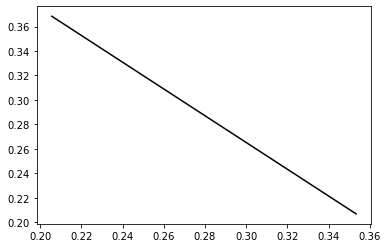

In [302]:
plt.plot(x, EBVasicekPoints,color='k')

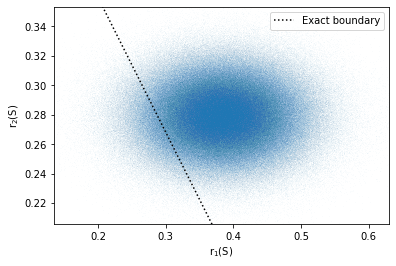

In [354]:
plt.scatter(VasicekList[0],VasicekList[1],s=0.00005)
line1Vas = plt.plot(EBVasicekPoints,x,color='k', lw=1.5,linestyle=':')
plt.gca()
plt.xlim(norm.ppf(1-0.9999, loc=EV1, scale=Var1), norm.ppf(0.9999, loc=EV1, scale=Var1))
plt.ylim(norm.ppf(1-0.9999, loc=EV2, scale=Var2), norm.ppf(0.9999, loc=EV2, scale=Var2))
plt.xlabel('r$_1$(S)')
plt.ylabel('r$_2$(S)')
plt.legend(line1Vas,['Exact boundary'],loc=1)
plt.show()

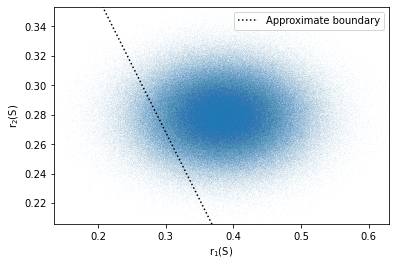

In [355]:
plt.scatter(VasicekList[0],VasicekList[1],s=0.00005)
line2Vas = plt.plot(ApproxEBVasicek(x),x,color='k', lw=1.5,linestyle=':')
plt.gca()
plt.xlim(norm.ppf(1-0.9999, loc=EV1, scale=Var1), norm.ppf(0.9999, loc=EV1, scale=Var1))
plt.ylim(norm.ppf(1-0.9999, loc=EV2, scale=Var2), norm.ppf(0.9999, loc=EV2, scale=Var2))
plt.xlabel('r$_1$(S)')
plt.ylabel('r$_2$(S)')
plt.legend(line2Vas,['Approximate boundary'],loc=1)
plt.show()

(-1.75e-06, 2.5e-07)

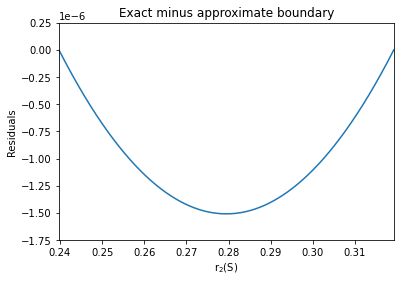

In [308]:
residualsVasicek = []
for i in range(len(EBVasicekPoints)):
    diff = EBVasicekPoints[i]-ApproxEBVasicek(x)[i]
    residualsVasicek.append(diff)
plt.plot(x,residualsVasicek)
plt.ylabel('Residuals')
plt.xlabel('r$_2$(S)')
plt.title('Exact minus approximate boundary')
plt.xlim(norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2), norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2))
plt.ylim(-1.75*10**(-6), 0.25*10**(-6))

In [ ]:
## CIR plots

In [382]:
def CIRJPDF(N):
    W_1 = []
    W_2 = []
    
    for i in range(N):
        r_new1 = X_1_new.rvs()
        r_new2 = X_2_new.rvs()
        W_1.append(r_new1)
        W_2.append(r_new2)
        
    return [W_1, W_2]

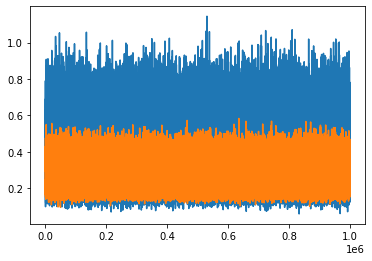

In [384]:
CIRList = CIRJPDF(1000000)
plt.plot(CIRList[0])
plt.plot(CIRList[1])
plt.show()

(0.09919996022356439, 0.9343016081325912)

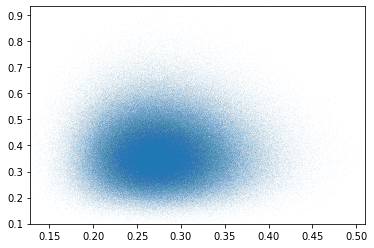

In [401]:
plt.scatter(CIRList[1],CIRList[0],s=0.00005)
plt.xlim(X_2_new.ppf(1-0.9999), X_2_new.ppf(0.9999))
plt.ylim(X_1_new.ppf(1-0.9999), X_1_new.ppf(0.9999))

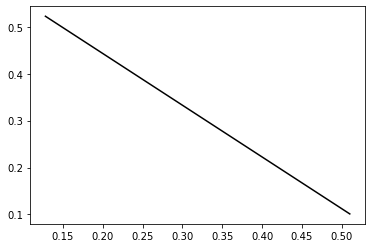

In [310]:
ApproxEBCIR = lambda x: coefCIR[0]*x+coefCIR[1]
x = np.linspace(X_2_new.ppf(1-0.9999),X_2_new.ppf(0.9999), 10000)
plt.plot(x, ApproxEBCIR(x),color='k')

In [311]:
EBCIR = lambda z : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*z+resultCIR.y[2,1]*w)-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*z+resultCIR.y[2,2]*w)-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*z+resultCIR.y[2,3]*w)-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*z+resultCIR.y[2,4]*w)-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*z+resultCIR.y[2,5]*w)
CIREB_init_guess = 0.2
EBCIRPoints = []
for i in range(len(x)):
    w = x[i]
    sol = fsolve(EBCIR, CIREB_init_guess)[0]
    EBCIRPoints.append(sol)

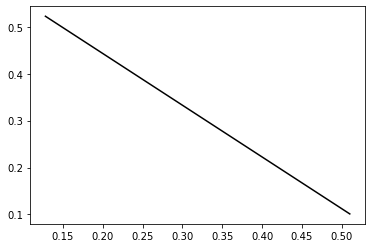

In [313]:
plt.plot(x, EBCIRPoints,color='k')

In [318]:
#very small residuals
EBCIRPoints[9999],ApproxEBCIR(X_2_new.ppf(0.9999)),EBCIRPoints[0],ApproxEBCIR(X_2_new.ppf(1-0.9999))

(0.10119952652570746,
 0.10114627341773841,
 0.5225552325127909,
 0.5225338224800233)

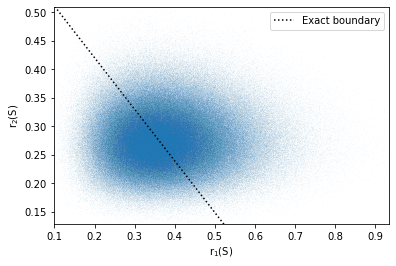

In [403]:
plt.scatter(CIRList[0],CIRList[1],s=0.00005)
line1CIR = plt.plot(EBCIRPoints,x,color='k', lw=1.5,linestyle=':')
plt.gca()
plt.xlim(X_1_new.ppf(1-0.9999), X_1_new.ppf(0.9999))
plt.ylim(X_2_new.ppf(1-0.9999), X_2_new.ppf(0.9999))
plt.xlabel('r$_1$(S)')
plt.ylabel('r$_2$(S)')
plt.legend(line1CIR,['Exact boundary'],loc=1)
plt.show()

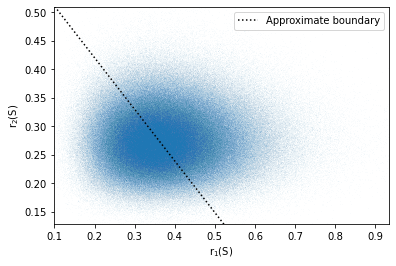

In [405]:
plt.scatter(CIRList[0],CIRList[1],s=0.00005)
line2CIR = plt.plot(ApproxEBCIR(x),x,color='k', lw=1.5,linestyle=':')
plt.gca()
plt.xlim(X_1_new.ppf(1-0.9999), X_1_new.ppf(0.9999))
plt.ylim(X_2_new.ppf(1-0.9999), X_2_new.ppf(0.9999))
plt.xlabel('r$_1$(S)')
plt.ylabel('r$_2$(S)')
plt.legend(line2CIR,['Approximate boundary'],loc=1)
plt.show()

(-1.7500000000000002e-05, 2.5e-06)

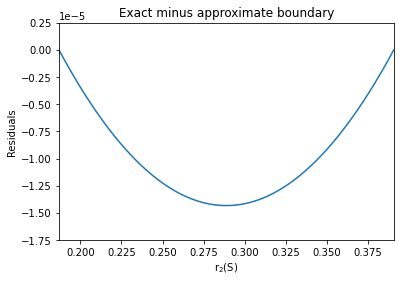

In [321]:
residualsCIR = []
for i in range(len(EBCIRPoints)):
    diff = EBCIRPoints[i]-ApproxEBCIR(x)[i]
    residualsCIR.append(diff)
plt.plot(x,residualsCIR)
plt.ylabel('Residuals')
plt.xlabel('r$_2$(S)')
plt.title('Exact minus approximate boundary')
plt.xlim(X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2))
plt.ylim(-1.75*10**(-5), 0.25*10**(-5))